# IF · MiniBatch K-means · LOF — 9가지 탐지 전략 비교

읽는 순서: **같은 데이터의 성능 → 시나리오별 차이 → 분포/판정선 → 탐지·오탐·미탐 사례 → 모델 전달**.

전체 모델, Adapter 전문가, 두 점수의 앙상블을 알고리즘마다 비교한다. 여기서 앙상블은
**IF+K-means+LOF 혼합이 아니라, 같은 알고리즘의 전체+Adapter 결합**이다.
이번 비교에서는 벤치마크를 바꾸지 않았다. 데이터 난도를 낮춘 효과를 모델 개선으로 계산하지 않는다.
과거에 이미 살펴본 합성 벤치마크이므로 외부 블라인드 운영 성능이라고 주장하지 않는다.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'code/model_research_v14/report.py').exists())
sys.path.insert(0, str(ROOT/'code'))
from model_research_v14 import report
report.setup()
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 70)
s = report.summary()
selection = report.read(ROOT/'reports/model_research_v14/selection.json')
display(s['protocol'])

{'model_sha256': '6e309b6d13c5beddba9cd5e35eab704a176a4a47181e2fc18a26fb19a75c71bc',
 'benchmark_manifest_sha256': '7f2dc4351af6166416f7694df97fb2050cab8d348e5b29d8451fcc36031f3b36',
 'no_refit_on_final': True,
 'point_adjustment': False,
 'decision_unit': 'one observed process stream minute',
 'benchmark_modified_in_this_experiment': False,
 'baseline': 'frozen v12 on exactly same current benchmark',
 'limitation': 'Adaptive research; not blind external production testing'}

## 1. 무엇을 몇 개 평가했나?

6개 시나리오는 각각 **5,000개 이상 사건 사례**, 혼합 Hard는 **1,000개 사례**다.
각 사례에는 정상 배경 로그와 이상 구간이 함께 있고, 별도의 정상 대조 로그가 있다.
STATUS=S여도 주입된 지연·폭주·중단 때문에 이상 정답일 수 있다.

아래 성능표의 분모는 CSV 행이나 사건 수가 아니라 **Process 업무 스트림의 1분 의사결정 수**다.
아무 로그도 없는 분을 보존하므로 입력 중단도 평가할 수 있다. 완료 로그만 받는 모델은 중단을 알 수 없다.

In [2]:
display(pd.DataFrame([{'시나리오': report.TASKS[d['dataset']], '이상 사례 수': d['case_count'],
    '평가 분 수': d['metrics'][0]['n'], '정상 분': d['metrics'][0]['normal'], '이상 분': d['metrics'][0]['anomaly']}
    for d in s['datasets']]))
display(Markdown(f"모든 분을 정상이라고 하면 Accuracy는 **{s['pooled'][0]['always_normal_accuracy']*100:.2f}%**다. Accuracy만으로 성능을 판단하지 않는다."))

,시나리오,이상 사례 수,평가 분 수,정상 분,이상 분
0,개별 지연,5000,59984,54914,5070
1,집단 지연,5000,363830,308737,55093
2,컬럼 관계,5000,60000,50000,10000
3,시간대 폭주,5000,398856,357193,41663
4,입력 중단,5000,502488,432498,69990
5,점진적 악화,5000,602814,452824,149990
6,혼합 Hard,1000,179794,139797,39997


모든 분을 정상이라고 하면 Accuracy는 **82.85%**다. Accuracy만으로 성능을 판단하지 않는다.

## 2. 전체 성능 — 9개 전략

- Precision: 경보 중 실제 이상 비율. 높아도 Recall이 낮으면 대부분 놓칠 수 있다.
- Recall: 이상 분 중 탐지한 비율. 오탐률과 같이 읽는다.
- F1: 두 지표의 조화 평균. 긴 점진적 악화 사건이 분 단위 합산을 많이 차지한다.
- 정상 오탐률: 정상 분 중 경보가 난 비율. 분 단위와 사건 단위 오탐은 다르다.

일반 막대그래프다. 알고리즘 3개 × 경로 3개이며, 아래는 전체 평가 분을 집계했다.

,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,2167766,85.02,63.13,30.41,41.05,3.68
1,IF Adapter,2167766,84.60,71.75,16.81,27.24,1.37
2,IF 앙상블,2167766,84.84,65.00,25.17,36.29,2.81
3,K-means 전체,2167766,85.13,64.62,29.43,40.44,3.34
4,K-means Adapter,2167766,84.03,57.29,27.12,36.81,4.19
5,K-means 앙상블,2167766,84.69,59.95,32.27,41.96,4.46
6,LOF 전체,2167766,83.96,59.94,19.50,29.43,2.70
7,LOF Adapter,2167766,83.90,58.60,20.93,30.84,3.06
8,LOF 앙상블,2167766,83.83,57.54,21.74,31.56,3.32


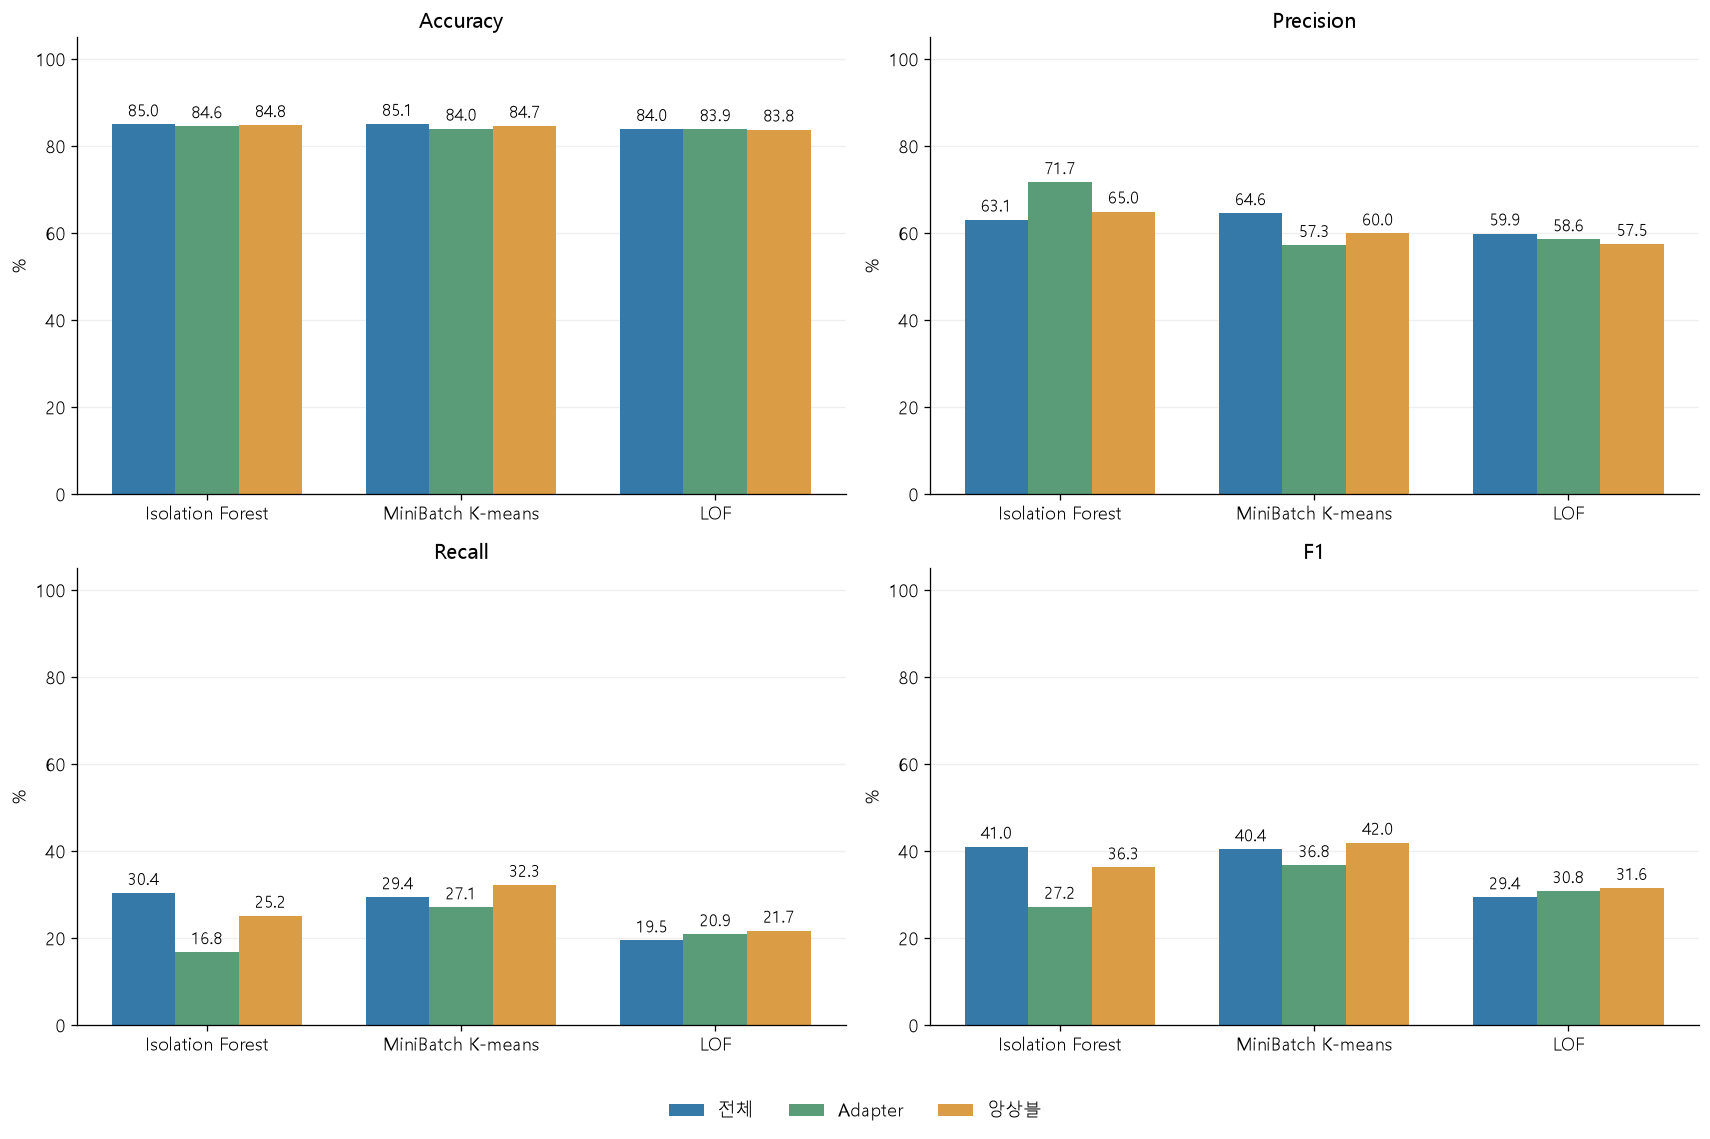

In [3]:
display(report.table(s['pooled']))
report.bars(); plt.show()

## 3. 기존 v12보다 실제로 좋아졌나?

아래 비교는 **현재 동일한 벤치마크**에서 기존 v12와 새 후보를 비교한다.
양의 F1 변화가 Precision 감소 또는 오탐 증가를 동반했는지 확인한다.
검증에서 기존 모델을 넘지 못한 후보는 자동 채택하지 않았다. LOF는 새 비교 대상이라 기존 수치가 없다.

**이번 IF 후보는 Recall/F1 중심의 tradeoff이지 네 지표의 전면 개선이 아니다.**
IF 전체 F1은 34.43%→41.05%지만 Precision은 77.50%→63.13%, 정상 오탐은 1.33%→3.68%다.
그래서 보수적인 운영 경보에는 기존 v12를 보존한다. K-means는 기존 v12와 예측이 동일하다.
LOF도 확인/탐색 경보 예산을 충족한 운영 대체품이라고 주장하지 않는다.

In [4]:
display(report.before_after())
display(pd.DataFrame([{'알고리즘': a, '선택 후보': r['candidate'], '새 임계값 보정': r['recalibrated'],
    '보정 문맥': r.get('mode'), '정상 분위수 (전체/Adapter/앙상블)': r.get('quantiles'),
    '검증 경보 예산 충족': r.get('within_budget', '기존 모델 보존'), '주의': r.get('warning', '')}
    for a, r in selection['families'].items()]))

,모델,Accuracy 변화 (%p),Precision 변화 (%p),Recall 변화 (%p),F1 변화 (%p),정상 오탐 변화 (%p),기존 F1 (%),새 F1 (%)
0,IF 전체,-0.52,-14.36,8.28,6.62,2.35,34.43,41.05
1,IF Adapter,-0.07,-4.39,1.39,1.59,0.37,25.65,27.24
2,IF 앙상블,-0.32,-7.16,3.22,2.62,1.05,33.67,36.29
3,K-means 전체,0.00,0.00,0.00,0.00,0.00,40.44,40.44
4,K-means Adapter,0.00,0.00,0.00,0.00,0.00,36.81,36.81
5,K-means 앙상블,0.00,0.00,0.00,0.00,0.00,41.96,41.96


,알고리즘,선택 후보,새 임계값 보정,보정 문맥,정상 분위수 (전체/Adapter/앙상블),검증 경보 예산 충족,주의
0,if,preserved_v12,True,phase,"[0.975, 0.995, 0.925]",True,
1,kmeans,preserved_v12,False,NaN,None,기존 모델 보존,
2,lof,anchored_k75,True,phase_eligibility,"[0.9995, 0.9995, 0.9995]",False,No candidate met development false-alarm budget; comparison only


## 4. 시나리오별 강점과 약점

합산 F1만 높여 특정 장애를 버리지 않았는지 확인한다. 왼쪽은 F1, 오른쪽은 정상 오탐률이다.
**점진적 악화의 낮은 F1을 입력 중단·폭주까지 모두 시계열 탐지가 안 된다고 해석하지 않는다.**
기본 6개 시나리오를 같은 비중으로 평균한 macro 성능도 합산과 따로 본다.

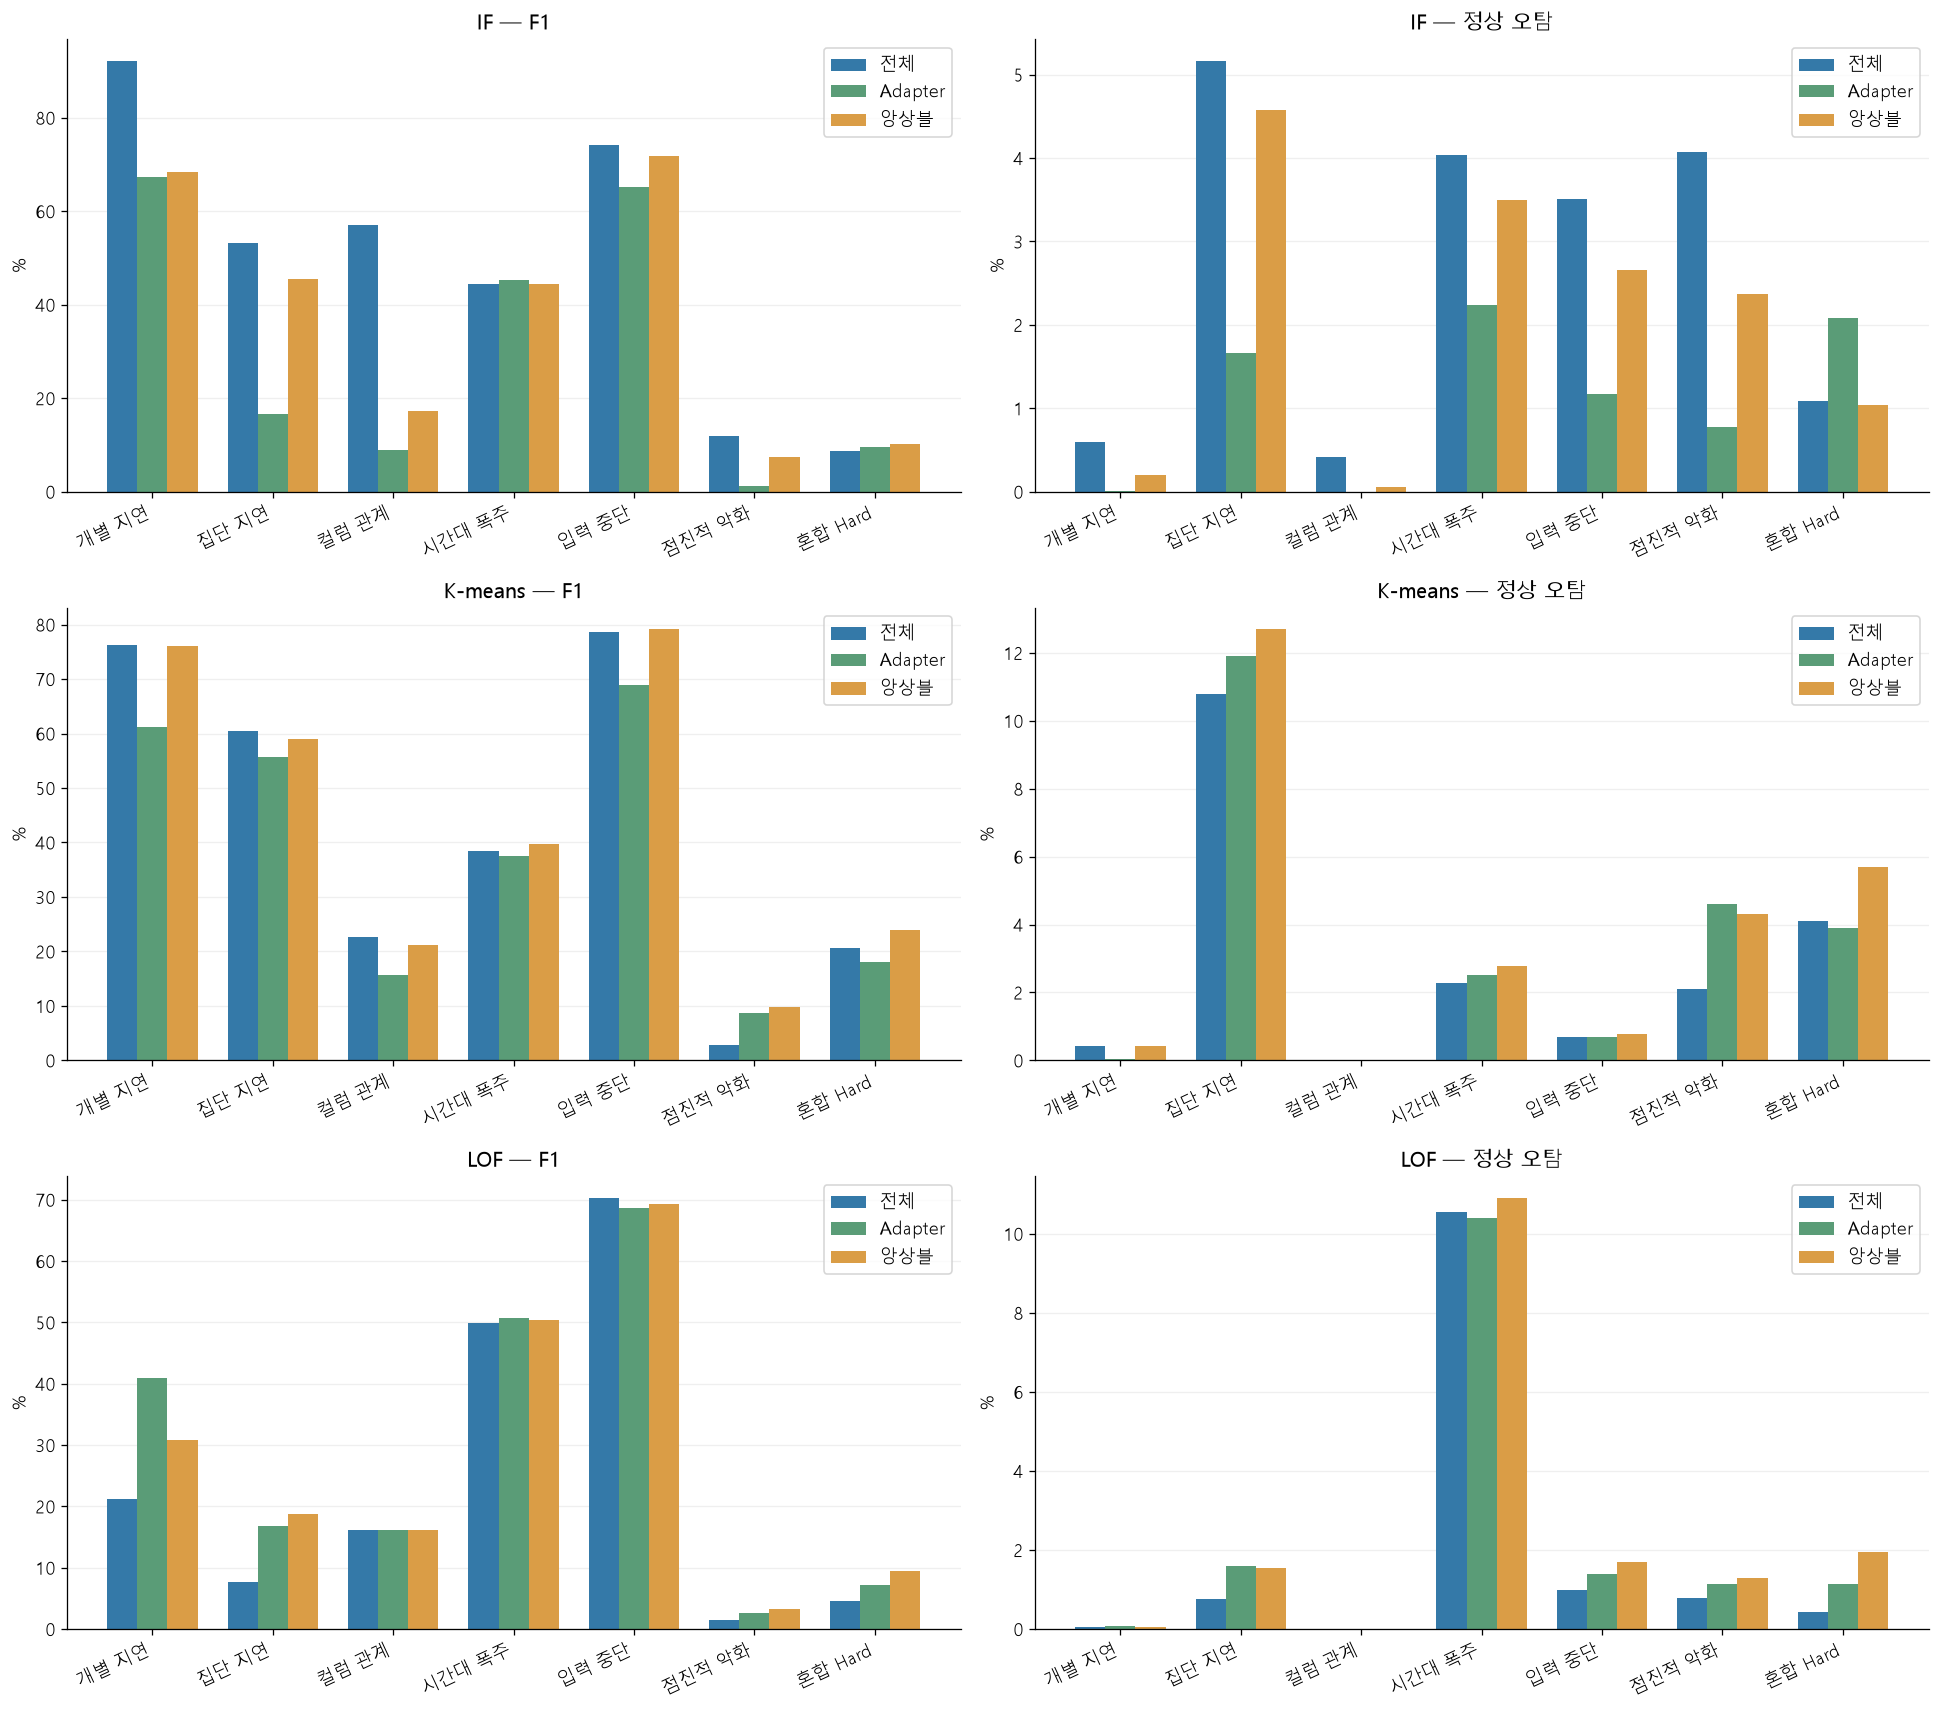

,시나리오,알고리즘,앙상블 F1 (%),Recall (%),정상 오탐 (%)
0,개별 지연,IF,68.34,53.00,0.19
1,개별 지연,K-means,76.00,64.02,0.41
2,개별 지연,LOF,30.88,18.38,0.06
3,집단 지연,IF,45.54,37.04,4.57
4,집단 지연,K-means,59.05,71.70,12.70
5,집단 지연,LOF,18.78,11.26,1.54
6,컬럼 관계,IF,17.27,9.48,0.06
7,컬럼 관계,K-means,21.17,11.84,0.00
8,컬럼 관계,LOF,16.16,8.79,0.00
9,시간대 폭주,IF,44.33,37.01,3.49


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,None,88.81,69.36,49.29,55.48,2.97
1,IF Adapter,None,87.18,70.85,25.49,34.12,0.98
2,IF 앙상블,None,87.47,70.73,34.32,42.47,2.22
3,K-means 전체,None,87.93,69.94,40.66,46.50,2.71
4,K-means Adapter,None,86.79,70.78,34.16,41.26,3.30
5,K-means 앙상블,None,87.57,70.73,42.12,47.49,3.49
6,LOF 전체,None,86.13,66.74,24.40,27.77,2.19
7,LOF Adapter,None,86.30,67.80,27.85,32.63,2.44
8,LOF 앙상블,None,86.17,68.35,27.30,31.46,2.58


In [5]:
report.scenario_bars(); plt.show()
display(report.characteristics())
display(report.table(s['basic_macro']))

### 모델의 성격 — 점수를 만드는 방법이 다르다

| 모델 | 이상 점수를 만드는 근거 | 기대하는 역할 | 주의점 |
|---|---|---|---|
| IF | 정상 벡터에서 드문 조합이 트리에서 쉽게 분리되는가 | 희귀 값/조합 후보 | 점수가 포화되면 작은 지속 변화가 잘 구분되지 않을 수 있음 |
| K-means | 정상 군집 중심에서 얼마나 먼가 | 정상 작동 유형의 중심에서 벗어남 | 넓은 정상 군집/거리 스케일에 민감 |
| LOF | 근처 정상 이웃보다 밀도가 얼마나 낮은가 | 전체 기준에서는 작아도 국소 정상 집단에서 드문 패턴 | 정상 표본 중복·희소 이웃·reference 크기에 민감, 추론 비용 증가 |

이것은 알고리즘의 원리다. 위 성능표의 실제 강점은 **피처·학습 표본·threshold까지 포함한 현재 설정**의 결과다.
세 모델 모두 시간창 피처를 입력받지만, 원시 시퀀스를 예측하는 신경망 모델은 아니다.

## 5. 입력 피처 분포를 먼저 보자

각 500사례 처리 청크에서 고정 seed로 최대 120개 분을 추출한 **설명용 표본**이다.
정상/이상 집단별 합이 100%인 일반 히스토그램이다. 표본은 실제 전체 빈도 비율의 추정치가 아니다.
실행 수와 소요시간만 `log(1+x)` 축으로 변환했다. 양끝 0.5%는 끝 막대에 합쳤고, 성능 집계에서는 자르지 않았다.

같은 소요시간도 업무·처리량에 따라 다르므로 조건부 소요시간 꼬리 피처가 필요하다.
누적 편차 분포가 다르더라도 실제 IF/K-means 검증 성능이 좋아지는지는 별개다.

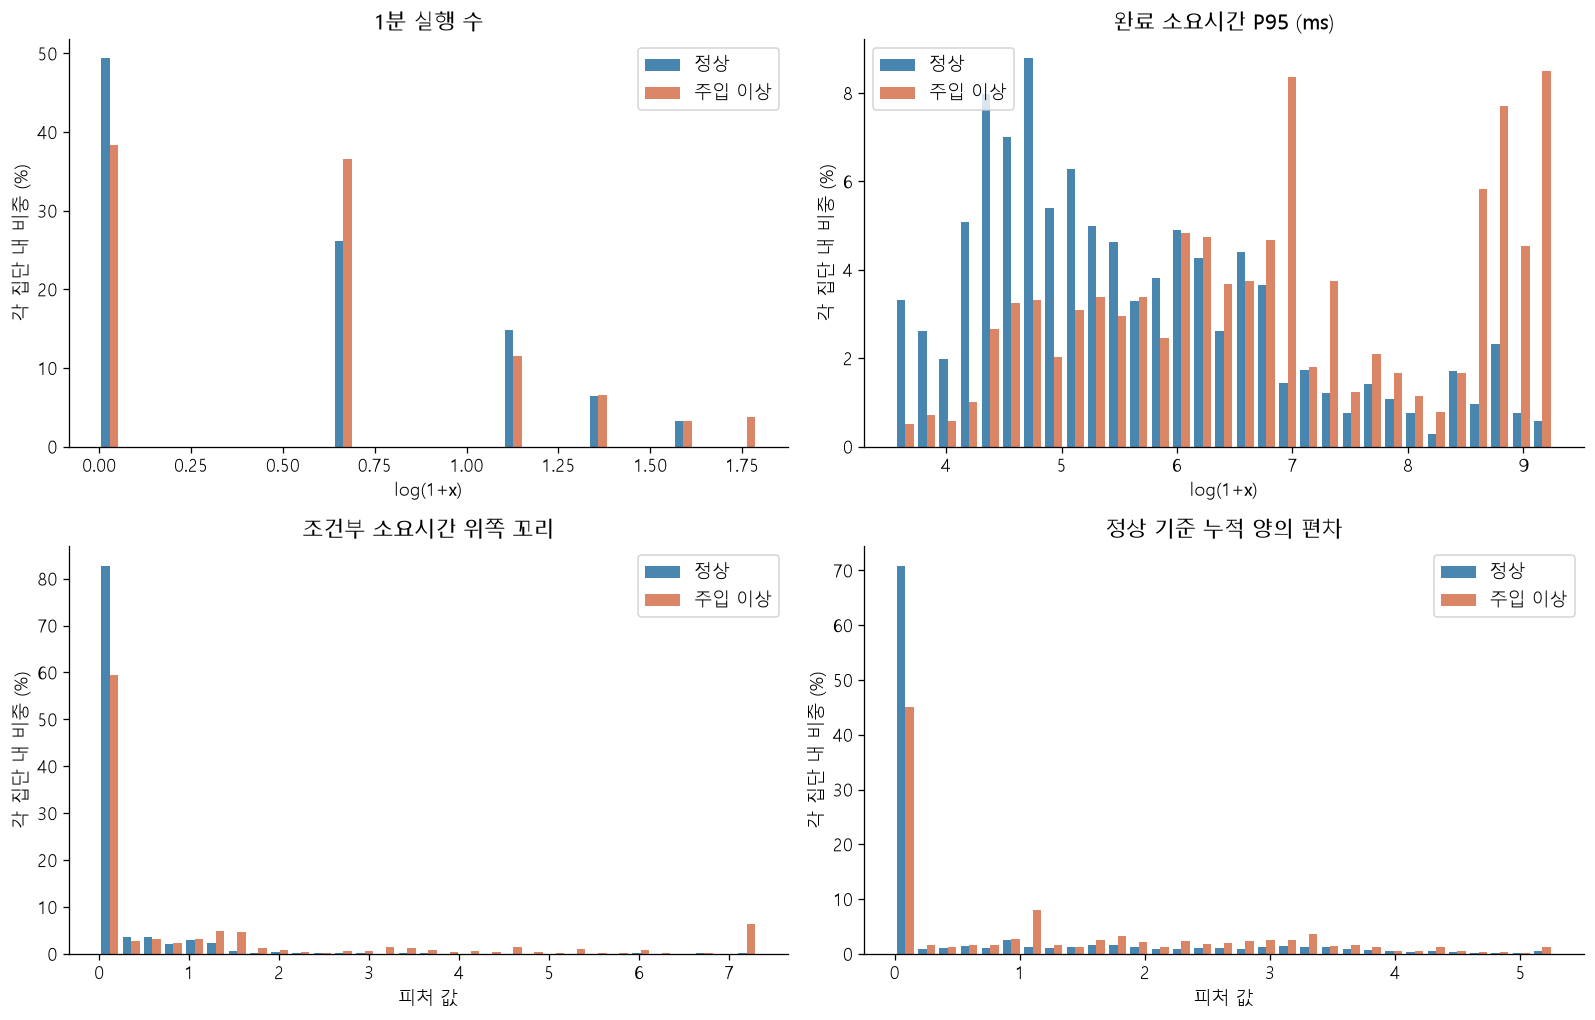

In [6]:
report.input_histograms(); plt.show()

## 6. 이상 점수 분포와 실제 판정선

X축은 **해당 모델 점수 − 해당 문맥의 threshold**다. 0보다 크면 이상이다.
점선 오른쪽 정상은 오탐, 왼쪽 주입 이상은 미탐이다. 0은 원래 LOF 비율이 0이라는 뜻이 아니다.
알고리즘별 score 단위가 달라 그래프의 절대 너비를 알고리즘 사이에서 비교하지 않는다.

파일당 최대 5,000분을 고정 seed로 추출했고, 양끝 0.5%는 끝 막대에 합쳤다.
각 집단의 합을 100%로 정규화해 정상 분이 많아서 이상 막대가 사라지는 문제를 줄였다.

0을 히스토그램 구간 경계로 고정했다. `margin = 0`인 동률은 실제로 정상 판정이므로 왼쪽 막대에 포함했다.
두 집단을 겹치지 않은 나란한 막대로 표시해 겹침 색을 읽어야 하는 불편을 줄였다.

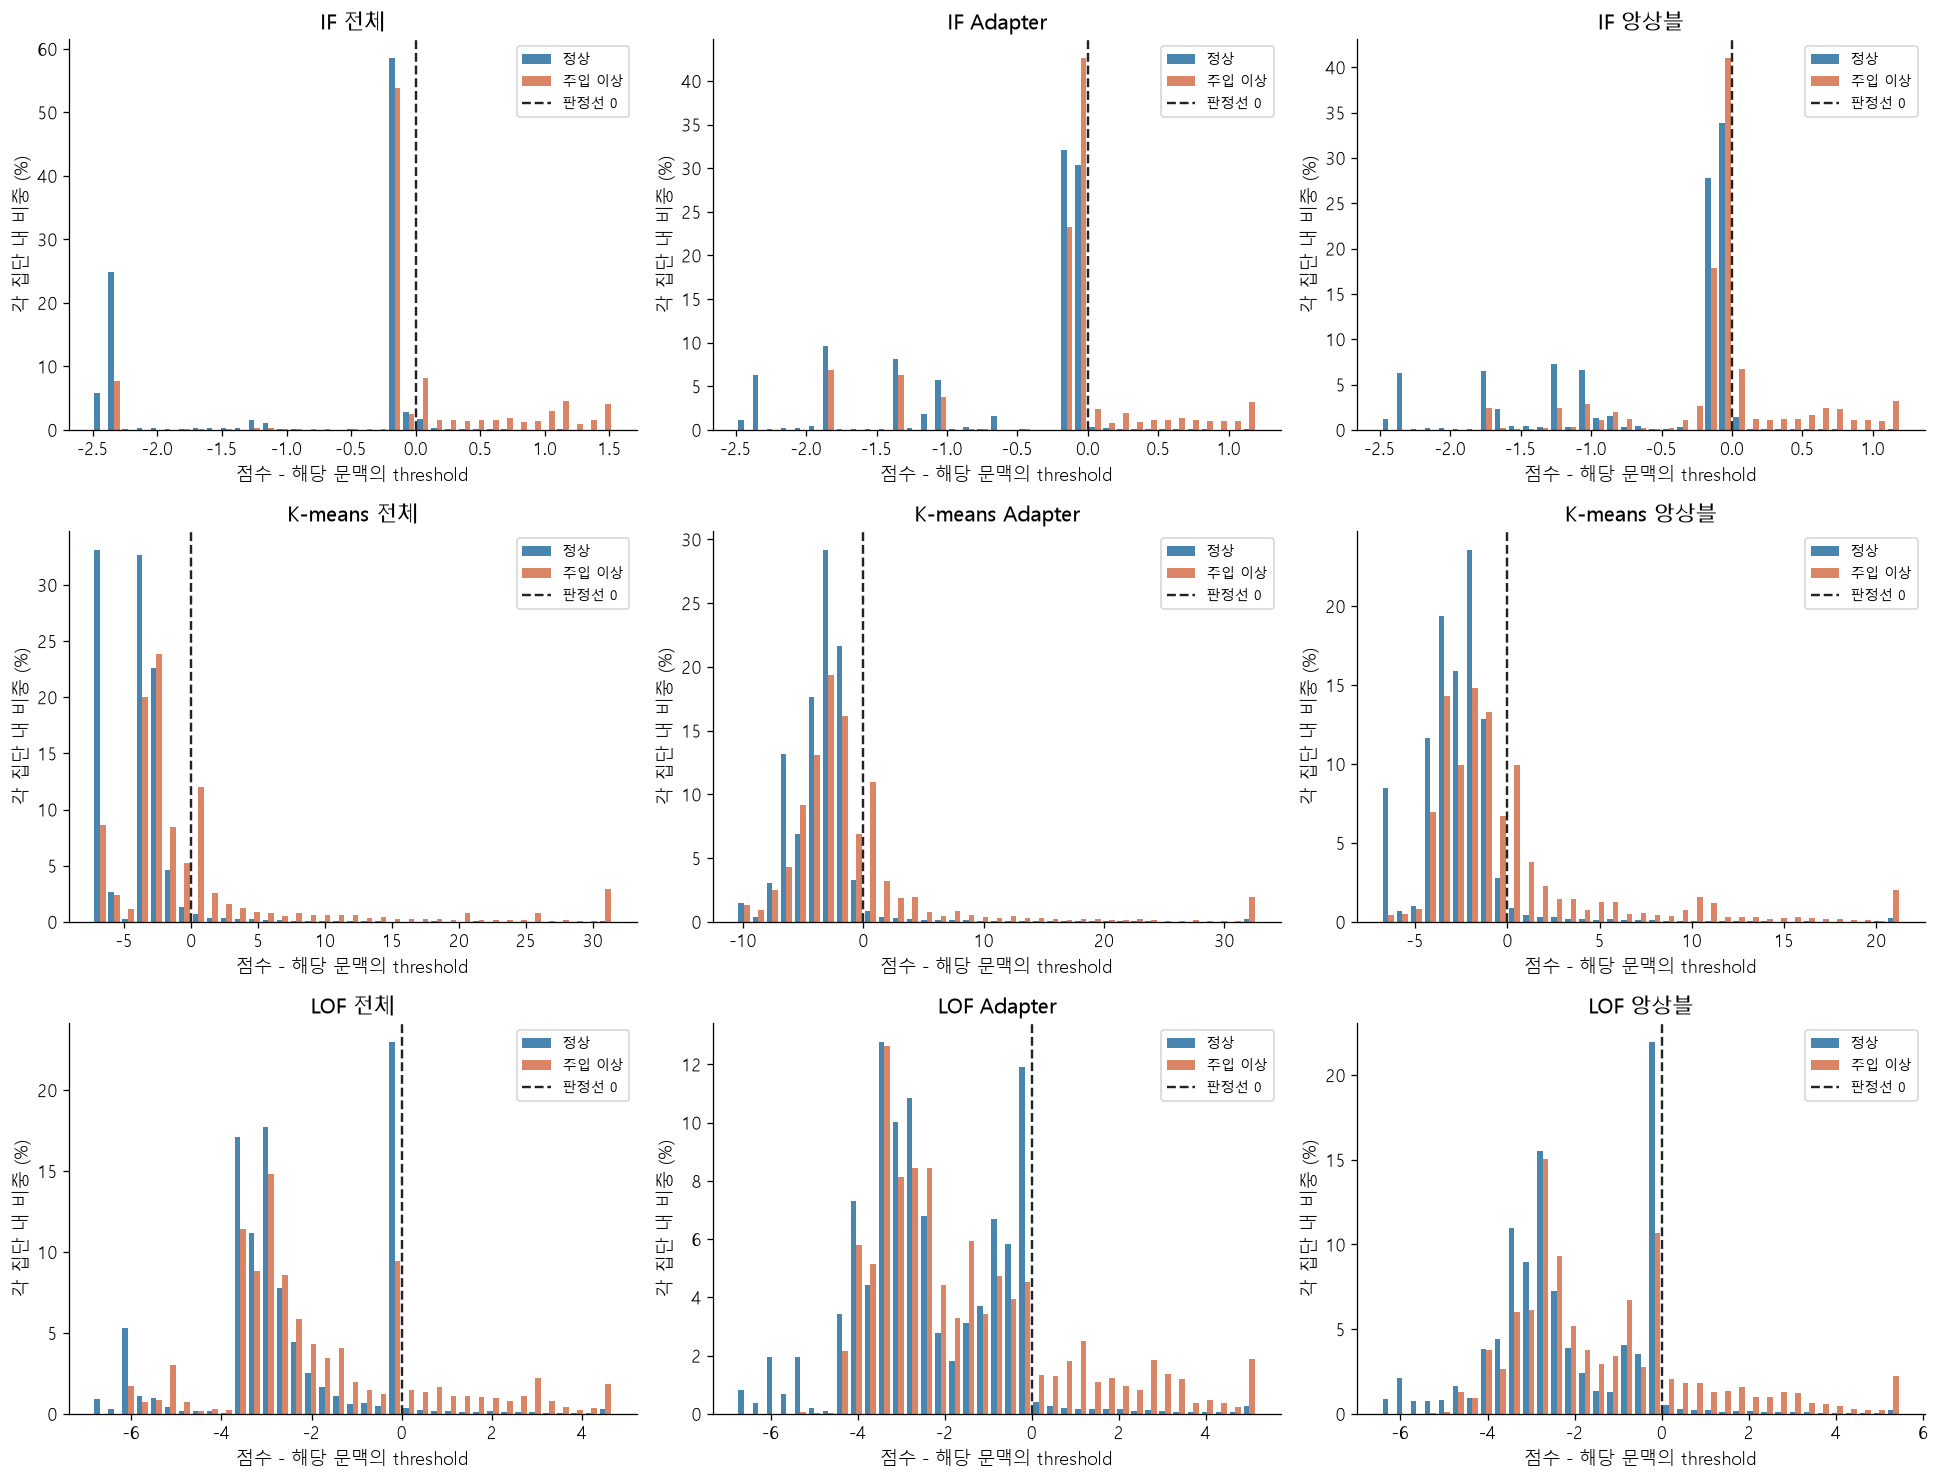

,알고리즘,경로,Adapter 문맥,단계,관측 gate,정상 분위수,기존 margin에 적용한 실제 threshold,보정 정상 분 수
0,if,전체,GLOBAL,startup,-1,0.9750,-0.16880,1350
1,if,전체,GLOBAL,steady,-1,0.9750,-0.01088,7594
12,if,Adapter,GLOBAL,startup,-1,0.9950,-0.16880,1350
13,if,Adapter,GLOBAL,steady,-1,0.9950,-0.01088,7594
24,if,앙상블,GLOBAL,startup,-1,0.9250,-0.16880,1350
25,if,앙상블,GLOBAL,steady,-1,0.9250,-0.01088,7594
36,lof,전체,GLOBAL,startup,0,0.9995,-1.46300,492
37,lof,전체,GLOBAL,startup,1,0.9995,5.27095,1350
84,lof,Adapter,GLOBAL,startup,0,0.9995,-1.46300,492
85,lof,Adapter,GLOBAL,startup,1,0.9995,5.27095,1350


,경로,단계,분기,정규화 threshold,앙상블 threshold
0,GLOBAL,startup,sparse <3 prior nonempty minutes,6.567778,6.567778
1,GLOBAL,steady,sparse <3 prior nonempty minutes,6.567778,6.567778
2,DB.READER,startup,sparse <3 prior nonempty minutes,2.000835,1.500626
3,DB.READER,steady,sparse <3 prior nonempty minutes,2.000835,1.500626
4,DB.WRITER,startup,sparse <3 prior nonempty minutes,2.741689,2.280698
5,DB.WRITER,steady,sparse <3 prior nonempty minutes,2.741689,2.280698
6,FILE.READER,startup,sparse <3 prior nonempty minutes,1.960979,1.470734
7,FILE.READER,steady,sparse <3 prior nonempty minutes,1.960979,1.470734
8,FILE.WRITER,startup,sparse <3 prior nonempty minutes,2.383947,1.787960
9,FILE.WRITER,steady,sparse <3 prior nonempty minutes,2.383947,1.787960


모든 보정 문맥의 실제 숫자는 handoff/manifest.json의 thresholds에 저장되어 있다. 기존 모델을 보존한 경로의 원래 threshold도 같은 파일에 포함된다.

In [7]:
report.score_histograms(); plt.show()
thresholds = report.threshold_table()
display(thresholds.groupby(['알고리즘','경로'], sort=False).head(2))
km_model = next(m for m in report.read(ROOT/'reports/model_research_v14/handoff/manifest.json')['models'] if m['algorithm']=='kmeans')
display(pd.DataFrame([{'경로': r['original'].get('route'), '단계': r['original'].get('phase'),
    '분기': r['original'].get('regime'), '정규화 threshold': r['original'].get('normalized_threshold'),
    '앙상블 threshold': r['original'].get('ensemble_threshold')} for r in km_model['thresholds']]).head(12))
display(Markdown('모든 보정 문맥의 실제 숫자는 handoff/manifest.json의 thresholds에 저장되어 있다. 기존 모델을 보존한 경로의 원래 threshold도 같은 파일에 포함된다.'))

### 임계값은 어떻게 정했나?

원본 정상 학습·calibration·threshold 템플릿 집단은 서로 분리했다.
새 검증 NORMAL 사례의 절반은 추가 정상 보정용, 나머지는 탐색 성능용으로 분리했다.
**정상 탐색 집단과는 분리했지만, 보정 정상 사례 270개의 paired 이상 사례는 탐색 집단에 남아 있었다.**
따라서 탐색을 완전한 사례 단위 독립 검증이라고 부르지 않는다. `case_partition_audit.json`에 분할 메타데이터 정정을 기록했다.
탐색에서 각 경로의 정상 분위수를 골랐으며, 확인 사례와 최종 벤치마크로 threshold를 다시 맞추지 않았다.
관측 단계/트래픽·완료 근거 여부에 따른 문맥 보정을 시험했다. 미지원 Adapter는 전체 threshold를 그대로 쓴다.

LOF는 `novelty=True`로 정상 reference에 fit하고 새로운 관측만 `score_samples`한다.
`contamination='auto'`의 sklearn 기본 offset을 최종 서비스 threshold로 쓰지 않았다.
`log(-score_samples)`의 보정 점수를 사용하므로 최종 판정선 0과 원래 LOF 비율 1은 다른 값이다.
검증에서 설정한 오탐 예산은 실제 운영 오탐률 보장이 아니다.

### 선택된 하이퍼파라미터

| 알고리즘 | 선택 설정 |
|---|---|
| IF | v12 tree/분기 보존. 조건부 sparse/established IF 설정 max_samples=256, rotations=1. 이번 변경은 별도 정상 보정의 전체/Adapter/앙상블 분위수 0.975/0.995/0.925 |
| K-means | v12 보존. 초기 sparse 채널 K=12, established 군집 K=6. 새 K/공분산 후보는 탈락 |
| LOF | k=75, Euclidean, novelty=True, contamination='auto', seed=42. 중복 reference 제거, 채널별 최대 2,048 reference. 기존 6개 트래픽 + 5개 조건부 지연 + 5개 누적 지연 피처를 2개 채널로 사용. 보정 분위수 0.9995/0.9995/0.9995 |

LOF reference cap은 **학습 참고 이웃 수의 상한**이지 평가 사례 수나 원본 데이터 수가 아니다.
Adapter의 실제 reference는 채널별 약 427~543개, 전체는 두 채널 각각 2,048개다.
초기/안정 분기의 IF 설정을 적은 것이며 v12 내부의 모든 보존된 보조 모델을 256개 표본으로 재학습했다는 뜻은 아니다.

## 7. 실제 탐지·오탐·미탐 사례

각 전략에서 찾은 TP/FP/FN 사례를 제시한다. 실제 판정 근거는 저장된 margin이 0을 넘었는지다.
실행 수·무실행 연속 길이·조건부 지연은 **설명 단서**이며, 인과적 원인이나 SHAP 기여도로 단정하지 않는다.
처음 발견된 사례들이다. 전체 사례의 대표 통계로 해석하지 않는다.

In [8]:
examples = pd.DataFrame(report.read(report.location()/'decision_examples.json'))
display(examples.groupby(['method','outcome'], sort=False).head(1)[['method','outcome','dataset','adapterType','score_minus_threshold','native_execution_arrivals',
                  'zero_run','duration_p95_ms','duration_upper_max_1m','expert_available']])

,method,outcome,dataset,adapterType,score_minus_threshold,native_execution_arrivals,zero_run,duration_p95_ms,duration_upper_max_1m,expert_available
0,if_global,TP,individual_delay,FILE.READER,1.154200,1.0,0.0,20354.000000,7.314553,True
4,if_global,FP,individual_delay,FILE.READER,1.154200,1.0,0.0,2855.999947,6.621406,True
8,if_global,FN,individual_delay,FILE.WRITER,-1.289912,1.0,0.0,749.000000,0.222811,True
12,if_adapter,TP,individual_delay,DB.UPDATER,1.462556,1.0,0.0,5752.000000,1.418082,False
16,if_adapter,FP,individual_delay,DB.WRITER,0.202579,1.0,0.0,2011.000156,5.278115,True
20,if_adapter,FN,individual_delay,FILE.WRITER,-1.327086,1.0,0.0,749.000000,0.222811,True
24,if_ensemble,TP,individual_delay,DB.UPDATER,1.462556,1.0,0.0,5752.000000,1.418082,False
28,if_ensemble,FP,individual_delay,SERVICE.EXECUTOR,0.024447,1.0,0.0,26.000023,-0.000000,True
32,if_ensemble,FN,individual_delay,FILE.WRITER,-0.955216,1.0,0.0,749.000000,0.222811,True
36,kmeans_global,TP,individual_delay,FILE.READER,41.788344,1.0,0.0,20354.000000,7.314553,True


## 8. Adapter 모델의 의미와 지원 범위

전체: 모든 학습 업무의 정상 패턴. Adapter: 해당 어댑터의 정상 패턴. 앙상블: 두 점수 결합.
새/희소 Adapter에는 전문가가 없으므로 **Adapter·앙상블 경로도 전체와 완전히 동일하게 fallback**한다.
Adapter별 표본 수는 더 많은 독립 원본 업무가 있다는 뜻과 같지 않다. 반복 재생 행 수와 원본 지원을 구분한다.
모델마다 지원 범위가 다르면 지원 표본의 분모도 달라진다.

In [9]:
manifest = report.read(ROOT/'reports/model_research_v14/handoff/manifest.json')
display(pd.DataFrame([{'알고리즘': m['algorithm'], '지원 Adapter': ', '.join(m['expert_adapters']),
    '모델 크기 (MiB)': m['bytes']/1024**2} for m in manifest['models']]).round(2))
display(report.table(s['supported_only']))
display(report.table(s['fallback_only']))

,알고리즘,지원 Adapter,모델 크기 (MiB)
0,if,"DB.READER, DB.WRITER, FILE.READER, FILE.WRITER, SERVICE.EXECUTOR",11.26
1,kmeans,"DB.READER, DB.WRITER, FILE.READER, FILE.WRITER, SERVICE.EXECUTOR",0.58
2,lof,"DB.READER, DB.WRITER, FILE.READER, FILE.WRITER, SERVICE.EXECUTOR",2.83


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,1096068,81.18,52.01,26.98,35.53,5.93
1,IF Adapter,1096068,80.34,36.29,2.99,5.52,1.25
2,IF 앙상블,1096068,80.83,50.37,17.74,26.24,4.16
3,K-means 전체,1096068,81.30,52.82,25.60,34.49,5.44
4,K-means Adapter,1096068,79.13,41.68,21.52,28.38,7.17
5,K-means 앙상블,1096068,80.42,48.53,30.62,37.55,7.73
6,LOF 전체,1096068,81.40,58.30,11.47,19.17,1.95
7,LOF Adapter,1096068,81.29,55.33,13.98,22.32,2.69
8,LOF 앙상블,1096068,81.14,53.30,15.42,23.92,3.22


,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,1071698,88.95,80.56,34.89,48.69,1.49
1,IF Adapter,1071698,88.95,80.56,34.89,48.69,1.49
2,IF 앙상블,1071698,88.95,80.56,34.89,48.69,1.49
3,K-means 전체,1071698,89.05,82.55,34.44,48.60,1.29
4,K-means Adapter,1071698,89.05,82.55,34.44,48.60,1.29
5,K-means 앙상블,1071698,89.05,82.55,34.44,48.60,1.29
6,LOF 전체,1071698,86.57,60.79,30.01,40.18,3.43
7,LOF Adapter,1071698,86.57,60.79,30.01,40.18,3.43
8,LOF 앙상블,1071698,86.57,60.79,30.01,40.18,3.43


## 9. 지속 장애는 사건 탐지율·지연도 읽자

사건 Recall은 이상 구간 중 한 번이라도 탐지한 사례 비율이다.
그 사건의 모든 분을 탐지한 것으로 바꾸는 **point adjustment는 하지 않았다**.
첫 탐지 지연의 중앙값은 **탐지된 사건만** 포함한다. 미탐 사건을 0초로 처리하지 않는다.
한 분의 작은 오탐률도 긴 정상 사건에서는 한 번 이상 경보가 나는 비율이 커질 수 있다.

In [10]:
display(report.event_table())
display(pd.DataFrame([{'시나리오': report.TASKS[d['dataset']], **d['events']['normal_case_false_alarm_rate']} for d in s['datasets']]).round(4))

,데이터셋,사건 종류,모델,사건 수,탐지 사건 수,사건 Recall (%),첫 탐지 지연 중앙값 — 탐지된 사건만 (초)
0,개별 지연,개별 지연,if_ensemble,5000,2687,53.74,60.0
1,개별 지연,개별 지연,kmeans_ensemble,5000,3246,64.92,60.0
2,개별 지연,개별 지연,lof_ensemble,5000,932,18.64,60.0
3,집단 지연,집단 지연,if_ensemble,5000,3488,69.76,60.0
4,집단 지연,집단 지연,kmeans_ensemble,5000,4640,92.80,120.0
5,집단 지연,집단 지연,lof_ensemble,5000,1058,21.16,180.0
6,컬럼 관계,컬럼 관계,if_ensemble,5000,948,18.96,60.0
7,컬럼 관계,컬럼 관계,kmeans_ensemble,5000,1184,23.68,60.0
8,컬럼 관계,컬럼 관계,lof_ensemble,5000,879,17.58,60.0
9,시간대 폭주,시간대 폭주,if_ensemble,5000,3511,70.22,120.0


,시나리오,if_global,if_adapter,if_ensemble,kmeans_global,kmeans_adapter,kmeans_ensemble,lof_global,lof_adapter,lof_ensemble
0,개별 지연,0.0656,0.0014,0.0214,0.0450,0.0030,0.0452,0.0070,0.0092,0.0068
1,집단 지연,0.1310,0.1156,0.2872,0.0762,0.0938,0.1384,0.0200,0.0742,0.0874
2,컬럼 관계,0.0414,0.0000,0.0058,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
3,시간대 폭주,0.2162,0.1808,0.2522,0.0510,0.0472,0.0682,0.0242,0.0518,0.0616
4,입력 중단,0.2072,0.1730,0.2512,0.0396,0.0332,0.0500,0.0130,0.0350,0.0454
5,점진적 악화,0.1876,0.1630,0.3286,0.1020,0.1310,0.1738,0.0278,0.1016,0.1190
6,혼합 Hard,0.3990,0.5040,0.3580,0.0720,0.1640,0.3100,0.0500,0.3390,0.3790


## 10. 새 확인 사례 — 튜닝에 쓰지 않은 결과

확인 사례는 모델·threshold를 정한 후 처음 평가한다. 확인 성능이 탐색보다 낮다면 일반화 문제가 남아 있는 것이다.
같은 원본 pool/생성기를 공유하므로 새로운 실제 운영 기간을 대신하지 못한다.

In [11]:
v = report.read(ROOT/'reports/model_research_v14/validation_results.json')
display(report.read(ROOT/'reports/model_research_v14/case_partition_audit.json'))
display(pd.concat([report.table(v[a]['confirmation']['pooled'], offset=i*3).assign(알고리즘=a)
    for i,a in enumerate(('if','kmeans','lof'))], ignore_index=True))

{'normal_calibration_cases': 270,
 'shared_with_observed_search_cases': 270,
 'shared_with_normal_search_cases': 0,
 'shared_with_confirmation_cases': 0,
 'original_selection_sha256': 'bbcecdb4f2acf4e2fbc72c8bc888a92cda3233ada8f8a8b8b53cf3848da05185',
 'corrected_selection_sha256': '3493a9166ddfe51a53714426c47bcabd7ff7006068cf90e006f6f5ba751ac82c',
 'model_sha256_unchanged': True,
 'model_refit': False,
 'metrics_changed': False,
 'next_experiment': 'Exclude BOTH observed and normal paired cases from search when calibration takes that case; obtain fresh confirmation before promotion.'}

,모델,평가 분 수,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%),알고리즘
0,IF 전체,35786,82.84,46.06,38.56,41.98,8.66,if
1,IF Adapter,35786,85.44,74.93,14.32,24.05,0.92,if
2,IF 앙상블,35786,84.45,53.62,24.95,34.05,4.14,if
3,K-means 전체,35786,85.30,56.59,37.26,44.93,5.48,kmeans
4,K-means Adapter,35786,81.71,42.21,37.00,39.43,9.71,kmeans
5,K-means 앙상블,35786,83.61,48.99,44.46,46.61,8.88,kmeans
6,LOF 전체,35786,84.45,54.65,19.77,29.04,3.15,lof
7,LOF Adapter,35786,83.50,47.61,25.23,32.98,5.33,lof
8,LOF 앙상블,35786,84.40,53.08,26.51,35.36,4.50,lof


## 11. 무엇을 시도했고 무엇을 채택하지 않았나?

1. 정상 train의 업무·처리량 기준 median/MAD를 고정한 누적 양의 편차·EWMA·지속 비율 피처.
   최근 기준이 이상을 따라 움직이는 위험을 줄이려는 실험이다. 정확한 CUSUM 제어도나 새 하드 룰은 아니다.
2. 중복 정상 벡터 제거, LOF k/거리/reference 한도 변경.
3. 기존 학습 범위의 서로 다른 원본 정상 템플릿으로 60분 스트림 다양성을 추가.
   새로 늘어난 창이 독립 원본 거래인 것은 아니다. 검증 템플릿을 fit에 넣지 않았다.
4. 독립 정상 사례로 단계/관측 여부별 threshold 보정.
5. IF max_samples·회전, K-means K·거리 공분산 후보.
   회전·군집 거리 변경은 이전에도 시도한 항목이며 이번에 처음 고려했다고 주장하지 않는다.

v13 실패 실험과 v14 탈락 후보를 남겼다. 새 버전이라는 이유로 F1이 낮아진 모델을 배포하지 않는다.

In [12]:
display(report.read(ROOT/'reports/model_research_v14/normal_diversity.json'))
search = report.read(ROOT/'reports/model_research_v14/search_results.json')
display(pd.DataFrame([{'알고리즘': r['algorithm'], '후보': r['candidate'], '문맥': r.get('mode'),
    '탐색 macro F1 (%)': r['objective']*100, '최대 경로 FPR (%)': r['worst_pooled_fpr']*100,
    '경보 예산 충족': r.get('within_budget')} for r in search if 'route_search' not in r]).round(2))

{'sha256': 'dd712baae7a0020f9fab55f6028d21c546404c88fee5dd6f0440159d637c4155',
 'partitions': {'train': {'old_windows': 9593,
   'additional_windows': 32560,
   'additional_streams': 540,
   'sampled_source_templates': 1012,
   'available_source_templates': 4448,
   'minutes_per_stream': 60},
  'calibration': {'old_windows': 11558,
   'additional_windows': 21686,
   'additional_streams': 360,
   'sampled_source_templates': 485,
   'available_source_templates': 1952,
   'minutes_per_stream': 60},
  'threshold': {'old_windows': 10358,
   'additional_windows': 19272,
   'additional_streams': 320,
   'sampled_source_templates': 494,
   'available_source_templates': 1917,
   'minutes_per_stream': 60}},
 'reserved_validation_templates_used': False,
 'final_controls_used': False,
 'normal_source_partition_disjoint': True,
 'synthetic_cadence': True,
 'new_independent_source_rows_created': False}

,알고리즘,후보,문맥,탐색 macro F1 (%),최대 경로 FPR (%),경보 예산 충족
0,if,preserved_v12,NaN,45.74,2.22,None
1,if,preserved_v12,phase,51.49,2.29,True
2,if,preserved_v12,phase_eligibility,47.17,1.89,True
3,if,persistent,phase,42.04,1.65,True
4,if,persistent,phase_eligibility,32.72,15.69,False
5,if,diverse_s512_r1_k6_radius,phase,43.47,2.49,True
6,if,diverse_s512_r1_k6_radius,phase_eligibility,48.56,2.46,True
7,if,diverse_s1024_r4_k6_radius,phase,40.69,3.42,False
8,if,diverse_s1024_r4_k6_radius,phase_eligibility,44.47,3.83,False
9,kmeans,preserved_v12,NaN,47.24,3.64,None


## 12. 논문·저널 근거와 이번 구현 범위

| 자료 | 참고한 내용 | 실제 적용 / 미적용 |
|---|---|---|
| [Breunig 등, LOF: Identifying Density-Based Local Outliers, SIGMOD 2000](https://sigmodrecord.org/?download_id=6631&smd_process_download=1) | 국소 이웃의 밀도 비교 | sklearn novelty LOF 구현. 중복 제거·reference cap은 이번 데이터에 대한 엔지니어링 선택이지 논문의 필수 설정이 아님 |
| [Hariri 등, Extended Isolation Forest, IEEE TKDE 2021](https://arxiv.org/abs/1811.02141) | 축 정렬 분할의 편향 | 기존 회전 후보 재검토. random-hyperplane EIF 전체를 구현한 것은 아님 |
| [NIST CUSUM Control Charts](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc323.htm) | 작은 지속 평균 변화의 누적 | 고정 정상 기준 누적 피처 실험. 제어 한계 보장이 있는 정식 CUSUM 탐지기 아님 |
| [Kim 등, Towards a Rigorous Evaluation of Time-series Anomaly Detection, AAAI 2022](https://arxiv.org/abs/2109.05257) | point adjustment의 과대평가 | 원시 분 단위 지표 보존, PA 미사용. 논문의 다른 탐지 모델은 재현하지 않음 |
| [Tatbul 등, Precision and Recall for Time Series, NeurIPS 2018](https://arxiv.org/abs/1803.03639) | 점 이상과 구간 이상의 평가 차이 | 사건 Recall·지연을 분 지표와 함께 보고. 논문의 range precision/recall 전체 공식을 재현하지 않음 |
| [Schmidl 등, Anomaly Detection in Time Series: A Comprehensive Evaluation, PVLDB 2022](https://timeeval.github.io/evaluation-paper/) | 알고리즘·이상 종류별 성능 차이 | 시나리오별 성능/추론 비용 분리. TimeEval 전체 벤치마크 재현은 아님 |

## 13. 남은 문제와 서비스 연결

데이터 누적·빈 시간창·지연 도착·신규 업무·실제 계절성·드리프트를 backend에서 관리해야 한다.
Process 파생 연속 분 grid와 완료 Process 로그가 입력이고 Transaction 테이블은 필요 없다.
신뢰된 joblib hash를 확인하고 로드한다. 모델 내부의 합성 prior는 실제 운영 이력으로 검증해야 한다.
이번 실험은 하드 룰을 바꾸거나 자동 배포하지 않았다.

기존 벤치마크 난도 조정 방향과 기존 results.ipynb 수정 대상은 사용자 확인 대기다.
이 파일은 새 실험의 독립 실행 결과이며 기존 노트북을 덮어쓰지 않았다.

In [13]:
display(pd.DataFrame([{'알고리즘': m['algorithm'], '파일': m['file'], '크기 bytes': m['bytes'], 'sha256': m['sha256']}
    for m in manifest['models']]))
display(manifest['dependencies'])
display(pd.DataFrame([{'알고리즘': a, **d['score_seconds']} for a, d in [(d['dataset'], d) for d in s['datasets']]]))

,알고리즘,파일,크기 bytes,sha256
0,if,if_v14_candidate.joblib,11809123,ecf5d70cd5c034473a6a7327b19c5b52e8d430138a2f31c4e84eb26bbc90c55d
1,kmeans,kmeans_v14_candidate.joblib,606381,b37644a5c71cb03a633c390ed50a60f707f59966ad18d141354ed3ad9f225286
2,lof,lof_v14_candidate.joblib,2967746,5c702ff86f1844abfab933d7950207f1511b4d0cabf25fe7c96571e4563a66c0


{'numpy': '2.5.3',
 'pandas': '3.0.6',
 'scikit-learn': '1.9.1',
 'scipy': '1.18.1',
 'joblib': '1.6.0'}

,알고리즘,if,kmeans,lof
0,individual_delay,8.363549,1.814944,3.275948
1,group_delay,15.754764,2.535202,20.296549
2,column_relation,5.495458,1.280664,2.242581
3,time_burst,13.618239,2.407540,17.503131
4,input_stop,14.882426,2.568597,20.424457
5,gradual_degradation,19.014259,2.823092,30.835854
6,mixed_hard,5.981870,0.888122,9.813837


## 14. 서로 다른 이상을 실제로 잡았나?

한 알고리즘만 탐지한 이상 분과 한 알고리즘만 낸 오탐을 함께 센다.
다른 모델이 놓친 이상을 LOF가 찾더라도 추가 오탐이 더 많을 수 있다.
그래서 무조건 세 모델의 경보를 OR해서 합치는 것은 개선으로 보장되지 않는다.

In [14]:
complement = report.read(report.location()/'complementarity.json')
display(pd.DataFrame(complement['records']))
display(complement['all_three_missed_anomaly_minutes'])

,route,algorithm,unique_true_positive_minutes,unique_false_positive_minutes,unique_tp_share_of_all_anomaly_minutes
0,global,if,24166,45438,0.064997
1,global,kmeans,23659,40602,0.063633
2,global,lof,9185,31235,0.024704
3,adapter,if,8169,12430,0.021971
4,adapter,kmeans,39444,58565,0.106088
5,adapter,lof,20993,38872,0.056463
6,ensemble,if,14839,31991,0.039911
7,ensemble,kmeans,37952,59601,0.102076
8,ensemble,lof,11197,40030,0.030115


{'global': 222177, 'adapter': 235563, 'ensemble': 219044}